# Random Forest

El **Random Forest** es un algoritmo de aprendizaje supervisado basado en el **ensamblado de múltiples árboles de decisión** combinando las predicciones de múltiples árboles individuales para generar un resultado final más preciso y robusto. Su objetivo es mejorar la precisión y robustez de las predicciones, tanto en tareas de clasificación como de regresión, reduciendo el sobreajuste (*overfitting*) que suelen presentar los árboles individuales.

El algoritmo de Random Forest surgió como una solución directa para mitigar una limitación clave de los Árboles de Decisión individuales: la propensión al sobreajuste (overfitting). Un solo árbol, si se le permite crecer con suficiente profundidad, puede memorizar los datos de entrenamiento (incluyendo su ruido) en lugar de aprender a generalizar la relación subyacente.

Al crear muchos árboles que trabajan en conjunto, el modelo se vuelve menos sensible a los datos ruidosos, logrando una mayor precisión y una notable resistencia al sobreajuste.

El éxito de Random Forest se basa en introducir intencionalmente una "doble aleatoriedad" durante el proceso de entrenamiento de cada árbol individual, asegurando que cada uno desarrolle una perspectiva ligeramente diferente del problema.

**¿Cómo funciona?**
- Construye un conjunto (o "bosque") de árboles de decisión independientes, cada uno entrenado sobre una muestra aleatoria (con reemplazo, *bootstrap*) de los datos originales.

- En cada nodo de cada árbol, la selección de la variable para dividir se realiza considerando solo un subconjunto aleatorio de las variables disponibles, lo que introduce diversidad entre los árboles.

- Para clasificación, cada árbol vota por una clase y la predicción final es la clase más votada (mayoría). Para regresión, se promedian las predicciones de todos los árboles.

**Ventajas principales:**
- Generalmente ofrece mayor precisión que un solo árbol de decisión.
- Es robusto frente al ruido y al sobreajuste.
- Puede manejar grandes cantidades de variables y datos.
- Permite estimar la importancia de cada variable en la predicción.

**Desventajas:**
- Menor interpretabilidad que un árbol único.
- Puede ser computacionalmente costoso con muchos árboles y datos muy grandes.

**Aplicaciones comunes:**  
Detección de fraudes, diagnóstico médico, clasificación de imágenes, predicción de abandono de clientes, análisis de crédito, entre otros.

**Resumen:**  
Random Forest es una técnica poderosa y versátil, ampliamente utilizada en la industria y la investigación por su capacidad para ofrecer predicciones precisas y estables en una amplia variedad de problemas.

## Los pasos para construir un Random Forest son:
### A. Muestreo de Datos (Bootstrapping)
En lugar de entrenar cada árbol con el conjunto de datos completo, el algoritmo utiliza una técnica llamada "muestreo de bolsa" o "bootstrapping".

Esto implica:

1. Se toma un subconjunto aleatorio del conjunto de datos original.
2. Este subconjunto se utiliza para entrenar un árbol individual.
3. Este proceso se repite, creando muchos árboles, cada uno basado en un subconjunto de datos ligeramente diferente

### B. Selección Aleatoria de Características
Cuando un árbol de decisión se está construyendo (definiendo sus nodos de división), normalmente buscaría la mejor división entre todas las características disponibles. Random Forest añade una capa extra de aleatoriedad:

1. Si el conjunto total de atributos es m, en cada división, el algoritmo solo considera un subconjunto aleatorio de k características (donde k < m).

2. El árbol debe elegir la mejor división dentro de este subconjunto limitado.
Esta variación constante en los datos de entrenamiento y las características utilizadas reduce la correlación entre los árboles y mejora la precisión general del modelo.

3. Predicción y Agregación
Una vez que se ha construido el "bosque" de n árboles, el algoritmo combina sus salidas para obtener una predicción robusta:

- **Para problemas de Clasificación**: Cada árbol "vota" por una clase. La predicción final se determina por la mayoría de los votos emitidos por todos los árboles.

- **Para problemas de Regresión**: Las salidas de todos los árboles se promedian para determinar el valor predicho final.

Accuracy (RF): 0.9580
ROC AUC (RF): 0.9950

Classification Report (RF):
              precision    recall  f1-score   support

           0       0.96      0.92      0.94        53
           1       0.96      0.98      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.95      0.95       143
weighted avg       0.96      0.96      0.96       143

Confusion Matrix (RF):
[[49  4]
 [ 2 88]]
OOB Score: 0.9624


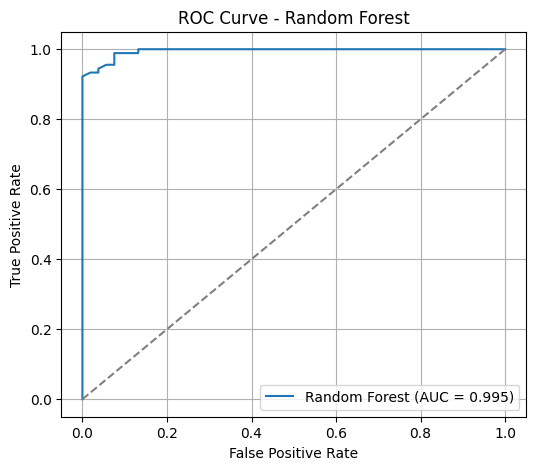

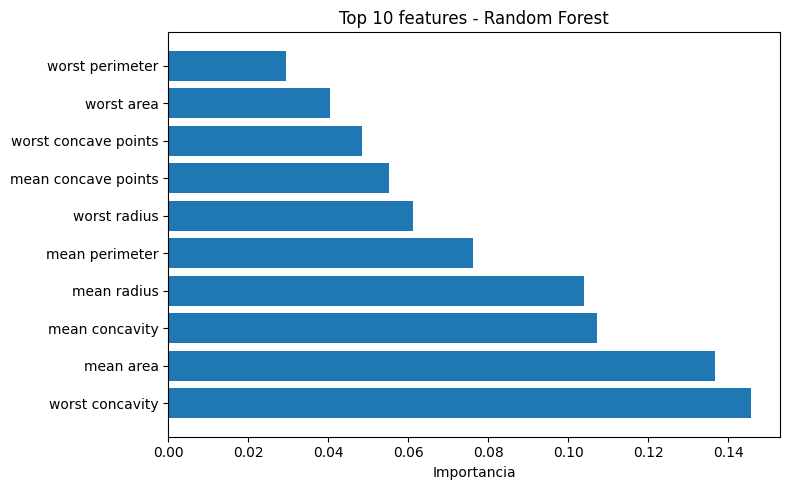

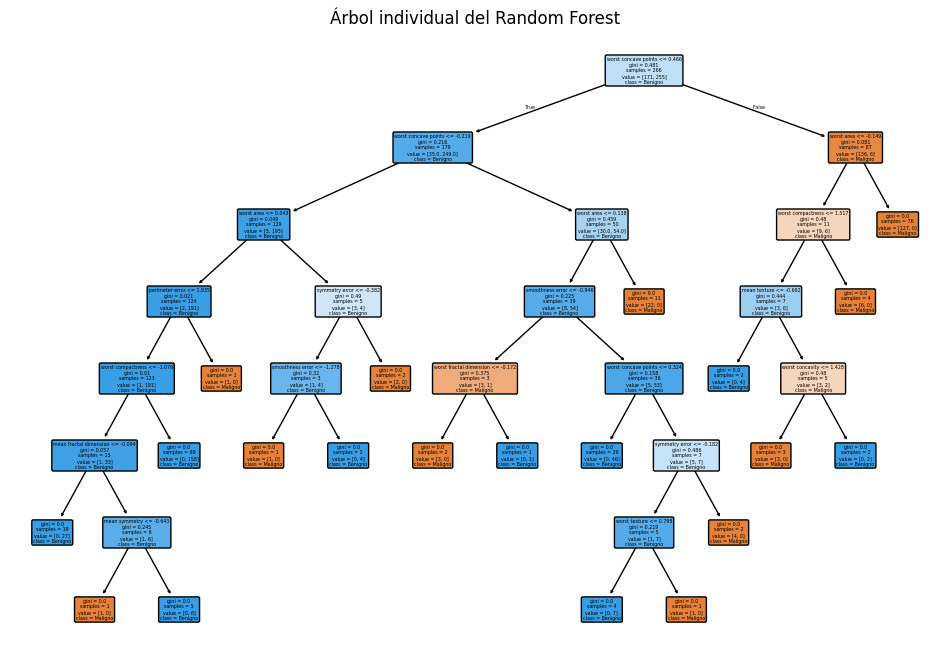

In [3]:
# Random Forest - clasificación sobre el dataset breast cancer (sklearn)
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
import numpy as np
import matplotlib.pyplot as plt

# Cargar datos
data = load_breast_cancer()
X_bc = data.data
y_bc = data.target
feature_names = data.feature_names

# División train/test
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.25, random_state=42, stratify=y_bc
)

# Escalado (opcional pero recomendado para muchos modelos)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_bc)
X_test_s = scaler.transform(X_test_bc)

# Definir y entrenar el modelo
rf_clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    n_jobs=-1,
    oob_score=True
)
rf_clf.fit(X_train_s, y_train_bc)

# Predicción y probabilidades
y_pred_rf = rf_clf.predict(X_test_s)
y_proba_rf = rf_clf.predict_proba(X_test_s)[:, 1]

# Métricas de evaluación
acc_rf = accuracy_score(y_test_bc, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test_bc, y_proba_rf)

print(f"Accuracy (RF): {acc_rf:.4f}")
print(f"ROC AUC (RF): {roc_auc_rf:.4f}")
print("\nClassification Report (RF):")
print(classification_report(y_test_bc, y_pred_rf))
print("Confusion Matrix (RF):")
print(confusion_matrix(y_test_bc, y_pred_rf))
if hasattr(rf_clf, "oob_score_"):
    print(f"OOB Score: {rf_clf.oob_score_:.4f}")

# Curva ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test_bc, y_proba_rf)
plt.figure(figsize=(6,5))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_rf:.3f})')
plt.plot([0,1], [0,1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.grid(True)
plt.show()

# Importancia de características (top 10)
importances_rf = rf_clf.feature_importances_
idxs_rf = np.argsort(importances_rf)[::-1][:10]
top_feats_rf = feature_names[idxs_rf]
top_vals_rf = importances_rf[idxs_rf]

plt.figure(figsize=(8,5))
plt.barh(np.arange(len(top_feats_rf))[::-1], top_vals_rf[::-1], align='center')
plt.yticks(np.arange(len(top_feats_rf)), top_feats_rf[::-1])
plt.xlabel('Importancia')
plt.title('Top 10 features - Random Forest')
plt.tight_layout()
plt.show()

# visualización de un árbol individual del bosque
plt.figure(figsize=(12,8))
plot_tree(rf_clf.estimators_[0], feature_names=feature_names, class_names=['Maligno', 'Benigno'], filled=True, rounded=True)
plt.title('Árbol individual del Random Forest')
plt.show()

Accuracy: 0.768160741885626
              precision    recall  f1-score   support

           0       0.79      0.89      0.84       437
           1       0.69      0.52      0.59       210

    accuracy                           0.77       647
   macro avg       0.74      0.70      0.72       647
weighted avg       0.76      0.77      0.76       647



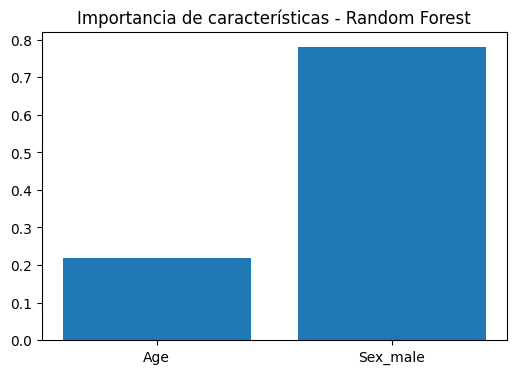

In [4]:
# Random Forest - clasificación sobre el dataset titanic
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Cargar y preparar datos
import requests

df = pd.read_csv('https://patricioaraneda.cl/public/titanic5_full.csv')
df = df[['Survived', 'Age', 'Sex']].dropna(subset=['Survived', 'Age', 'Sex'])
# Codificar sexo (male=1, female=0)
df['Sex_male'] = df['Sex'].map({'male': 1, 'female': 0})
# Características y etiqueta
X_t = df[['Age', 'Sex_male']].values
y_t = df['Survived'].astype(int).values
# División entrenamiento/prueba
X_train, X_test, y_train, y_test = train_test_split(X_t, y_t, test_size=0.3, random_state=42, stratify=y_t)
# Entrenar Random Forest
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=0)
rf_clf.fit(X_train, y_train)
# Evaluación
y_pred = rf_clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
# Importancia de características
importances = rf_clf.feature_importances_
feature_names = ['Age', 'Sex_male']
plt.figure(figsize=(6,4))
plt.bar(feature_names, importances)
plt.title('Importancia de características - Random Forest')
plt.show()  


In [5]:
# genera predicciones para pasajeros con diferentes edades y sexos
sample_passengers = np.array([[22, 0],  # 22 años, masculino
                              [30, 1],  # 30 años, femenino
                              [40, 1],  # 40 años, femenino
                              [35, 0]]) # 35 años, masculino
predictions = rf_clf.predict(sample_passengers)
print("Predicciones de supervivencia para pasajeros de diferentes edades y sexos:")
for i, passenger in enumerate(sample_passengers):
    age, sex = passenger
    survival = 'Sobrevive' if predictions[i] == 1 else 'No Sobrevive'
    print(f"{age} años y sexo {'masculino' if sex == 1 else 'femenino'}: {survival}")

Predicciones de supervivencia para pasajeros de diferentes edades y sexos:
22 años y sexo femenino: Sobrevive
30 años y sexo masculino: No Sobrevive
40 años y sexo masculino: No Sobrevive
35 años y sexo femenino: Sobrevive


### Comparativa entre Árbol de Decisión Individual y Random Forest.

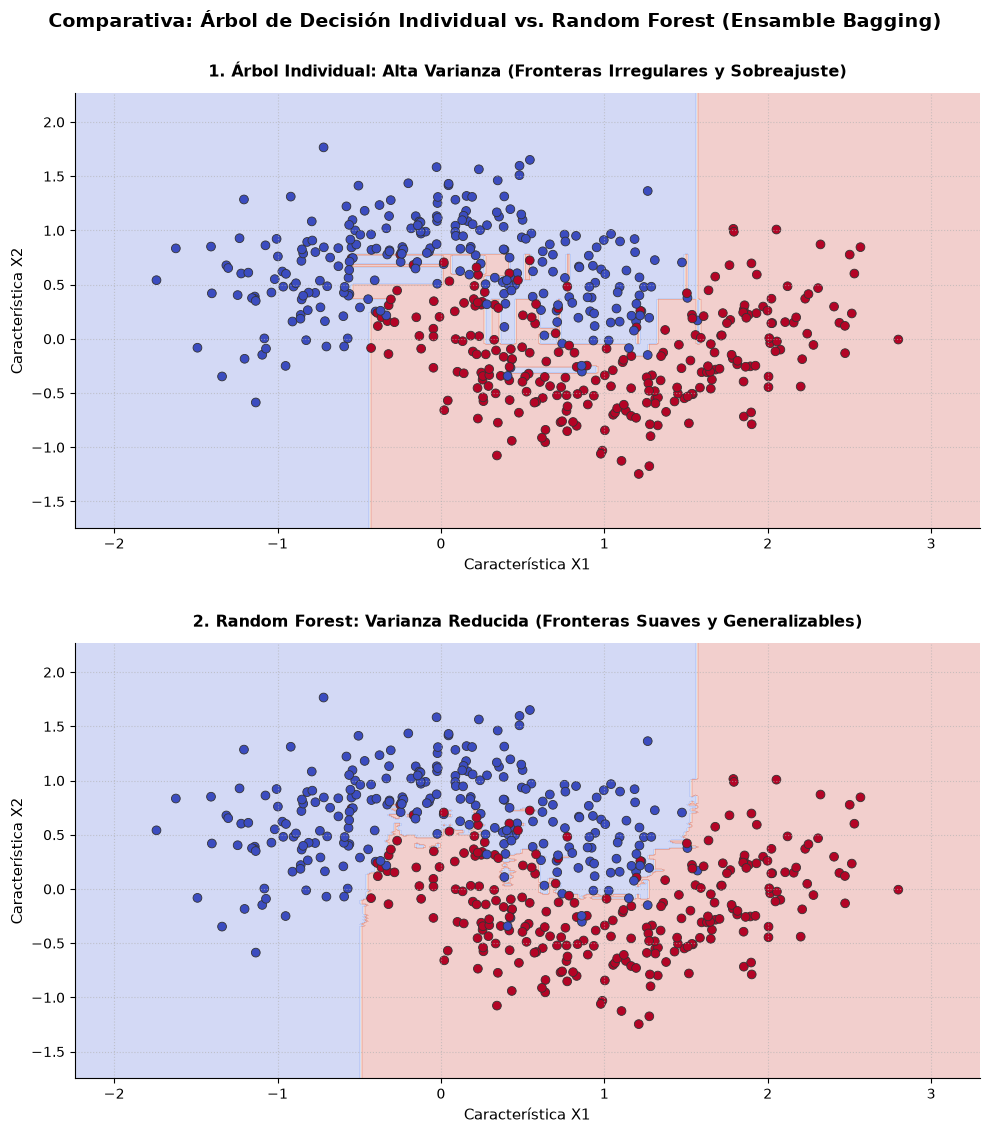

In [12]:
"""
Comparativa entre Árbol de Decisión Individual y Random Forest.
Demostración de regularización implícita por reducción de varianza.
Librerías: scikit-learn y matplotlib.
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Generación de un conjunto de datos sintético no lineal con ruido
X, y = make_moons(n_samples=500, noise=0.30, random_state=42)

# 2. Ajuste de modelos
# Árbol individual no restringido (memoriza ruido y genera bordes angulares irregulares)
arbol_individual = DecisionTreeClassifier(random_state=42)
arbol_individual.fit(X, y)

# Random Forest con 100 estimadores independientes (Bagging + Feature Subsampling)
bosque_aleatorio = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
bosque_aleatorio.fit(X, y)

# 3. Generación de la malla bidimensional para evaluar fronteras de decisión
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

# Inferencia de probabilidades sobre la malla
Z_dt = arbol_individual.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
Z_rf = bosque_aleatorio.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 4. Generación Gráfica Comparativa (Fondo Blanco Plano y Paleta Contrastada)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12), facecolor='white')

# Panel 1: Árbol de Decisión Individual
ax1.set_facecolor('white')
ax1.contourf(xx, yy, Z_dt, alpha=0.25, cmap=plt.cm.coolwarm)
ax1.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='#333333', linewidth=0.6, s=40)
ax1.set_title("1. Árbol Individual: Alta Varianza (Fronteras Irregulares y Sobreajuste)",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Característica X1", fontsize=10.5)
ax1.set_ylabel("Característica X2", fontsize=10.5)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)


# Panel 2: Random Forest (Ensamble)
ax2.set_facecolor('white')
ax2.contourf(xx, yy, Z_rf, alpha=0.25, cmap=plt.cm.coolwarm)
ax2.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='#333333', linewidth=0.6, s=40)
ax2.set_title("2. Random Forest: Varianza Reducida (Fronteras Suaves y Generalizables)",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Característica X1", fontsize=10.5)
ax2.set_ylabel("Característica X2", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

fig.suptitle("Comparativa: Árbol de Decisión Individual vs. Random Forest (Ensamble Bagging)",
             fontsize=13.5, fontweight='bold', y=0.94)

plt.tight_layout(rect=[0, 0, 1, 0.94], h_pad=3)
plt.show()

### IMportancia de una variable

=== TOP 5 CARACTERÍSTICAS MÁS DISCRIMINANTES ===
            Variable  Árbol_MDI  RandomForest_MDI  RandomForest_Permutacion_Test
worst concave points   0.132649          0.158955                      -0.009942
          worst area   0.000000          0.146962                      -0.001170
     worst perimeter   0.000000          0.085793                      -0.007602
        worst radius   0.733864          0.078952                      -0.002924
         mean radius   0.000000          0.077714                      -0.008772


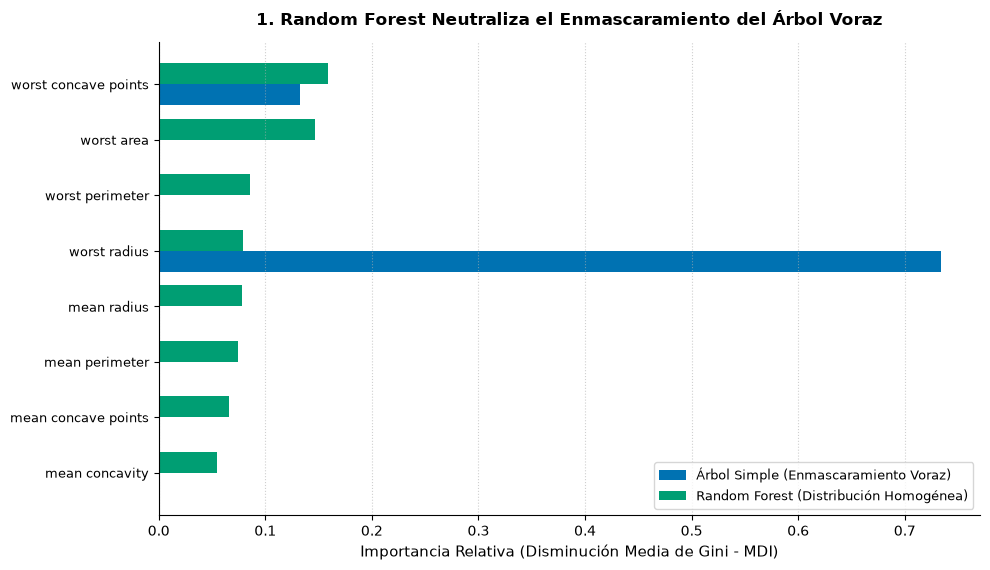

Gráfico 1 (MDI) generado con éxito.


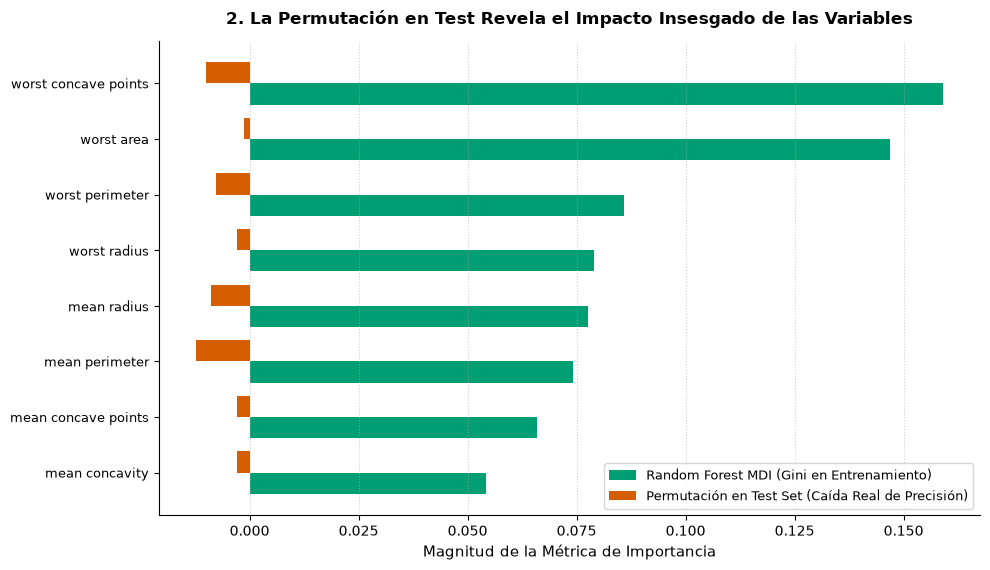

In [17]:
"""
Evaluación y Comparación de Importancia de Variables en Python.
Generación de dos gráficos independientes:
  1. Gráfico 1: MDI en Árbol Simple vs. Random Forest (Efecto de Enmascaramiento).
  2. Gráfico 2: MDI en Entrenamiento vs. Permutación en Datos de Prueba (Test Set).
Dataset: Breast Cancer Wisconsin (scikit-learn) - Datos Clínicos Reales.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# ==============================================================================
# 1. Carga de Datos Clínicos Reales y Partición Estratificada
# ==============================================================================
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Partición 70% Entrenamiento y 30% Prueba independiente
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Ajuste del Árbol Individual vs. Ensamble Random Forest
# ==============================================================================
# Árbol de decisión único con profundidad controlada
arbol_individual = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol_individual.fit(X_train, y_train)

# Random Forest con 100 estimadores y subespacios aleatorios (max_features='sqrt')
bosque_aleatorio = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
bosque_aleatorio.fit(X_train, y_train)

# ==============================================================================
# 3. Cálculo de Métricas: MDI (Entrenamiento) vs. Permutación (Prueba)
# ==============================================================================
# Disminución Media de Impureza de Gini (MDI) calculada en el ajuste
dt_mdi = arbol_individual.feature_importances_
rf_mdi = bosque_aleatorio.feature_importances_

# Permutation Feature Importance evaluada en datos de PRUEBA (10 repeticiones)
perm_result = permutation_importance(
    bosque_aleatorio, X_test, y_test,
    n_repeats=10,
    random_state=42,
    scoring='accuracy'
)
rf_perm = perm_result.importances_mean

# 5. Formato estructurado para auditoría de variables
df_imp = pd.DataFrame({
    'Variable': X.columns,
    'Árbol_MDI': dt_mdi,
    'RandomForest_MDI': rf_mdi,
    'RandomForest_Permutacion_Test': rf_perm
}).sort_values(by='RandomForest_MDI', ascending=False)

print("=== TOP 5 CARACTERÍSTICAS MÁS DISCRIMINANTES ===")
print(df_imp.head(5).to_string(index=False))

# Seleccionamos el Top 8 de variables más discriminantes según Random Forest
top_indices = np.argsort(rf_mdi)[-8:]
variables_top = [X.columns[i] for i in top_indices]

y_pos = np.arange(len(variables_top))
altura_barra = 0.38

# ==============================================================================
# 4. GRÁFICO 1 (SEPARADO): MDI Árbol Simple vs. Random Forest
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(10, 5.8), facecolor='white')
ax1.set_facecolor('white')

# Barras horizontales emparejadas
ax1.barh(
    y_pos - altura_barra / 2, [dt_mdi[i] for i in top_indices],
    height=altura_barra, color='#0072b2', label='Árbol Simple (Enmascaramiento Voraz)'
)
ax1.barh(
    y_pos + altura_barra / 2, [rf_mdi[i] for i in top_indices],
    height=altura_barra, color='#009e73', label='Random Forest (Distribución Homogénea)'
)

ax1.set_yticks(y_pos)
ax1.set_yticklabels(variables_top, fontsize=9.5)
ax1.set_xlabel("Importancia Relativa (Disminución Media de Gini - MDI)", fontsize=10.5)
ax1.set_title("1. Random Forest Neutraliza el Enmascaramiento del Árbol Voraz",
              fontsize=12, fontweight='bold', pad=12)

ax1.grid(True, axis='x', linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()
print("Gráfico 1 (MDI) generado con éxito.")

# ==============================================================================
# 5. GRÁFICO 2 (SEPARADO): MDI en Train vs. Permutación en Test
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(10, 5.8), facecolor='white')
ax2.set_facecolor('white')

# Barras horizontales emparejadas
ax2.barh(
    y_pos - altura_barra / 2, [rf_mdi[i] for i in top_indices],
    height=altura_barra, color='#009e73', label='Random Forest MDI (Gini en Entrenamiento)'
)
ax2.barh(
    y_pos + altura_barra / 2, [rf_perm[i] for i in top_indices],
    height=altura_barra, color='#d55e00', label='Permutación en Test Set (Caída Real de Precisión)'
)

ax2.set_yticks(y_pos)
ax2.set_yticklabels(variables_top, fontsize=9.5)
ax2.set_xlabel("Magnitud de la Métrica de Importancia", fontsize=10.5)
ax2.set_title("2. La Permutación en Test Revela el Impacto Insesgado de las Variables",
              fontsize=12, fontweight='bold', pad=12)

ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()


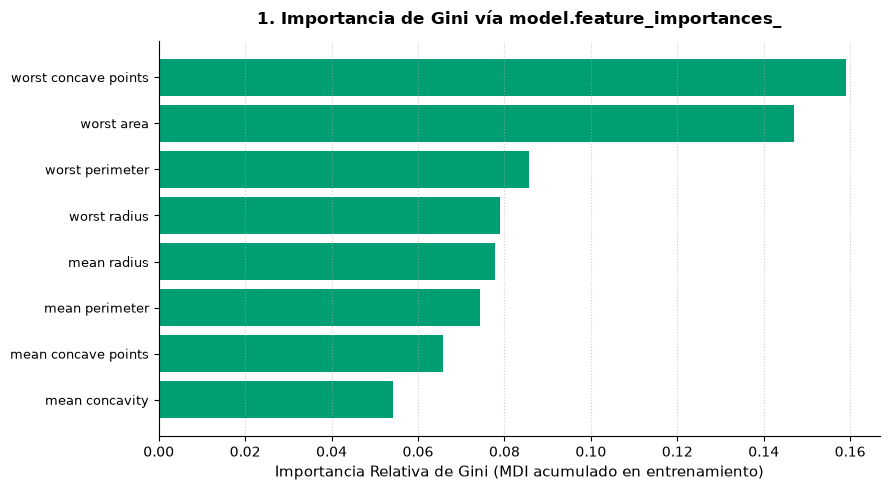

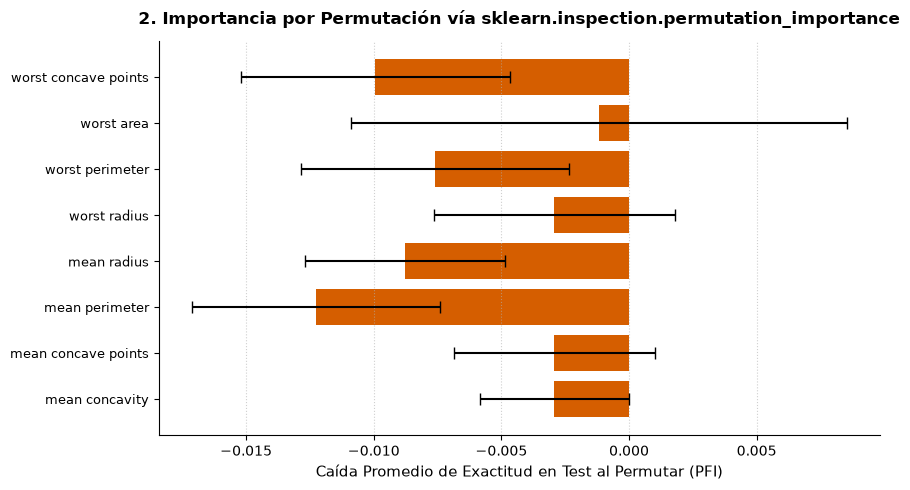

In [18]:
"""
Medición de Importancia de Variables en Random Forest con Scikit-Learn.
Compara:
  1. Atributo model.feature_importances_ (MDI - Gini en Entrenamiento)
  2. Función sklearn.inspection.permutation_importance (PFI - Permutación en Prueba)
Dataset: Breast Cancer Wisconsin (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# 1. Carga de datos reales y partición de entrenamiento/prueba
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Entrenamiento del Random Forest
bosque = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
bosque.fit(X_train, y_train)

# ------------------------------------------------------------------------------
# MÉTODO 1: Atributo .feature_importances_ (Gini / MDI)
# ------------------------------------------------------------------------------
importancias_gini = bosque.feature_importances_

# ------------------------------------------------------------------------------
# MÉTODO 2: Función permutation_importance (Prueba / PFI)
# ------------------------------------------------------------------------------
perm_res = permutation_importance(
    estimator=bosque,
    X=X_test,
    y=y_test,
    scoring='accuracy',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)
importancias_perm = perm_res.importances_mean

# Seleccionamos las 8 variables con mayor impacto según Random Forest
top_idx = np.argsort(importancias_gini)[-8:]
variables_top = [X.columns[i] for i in top_idx]

# ==============================================================================
# GRÁFICO 1: Importancia de Gini (Atributo feature_importances_)
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(9, 5), facecolor='white')
ax1.set_facecolor('white')

ax1.barh(range(len(top_idx)), importancias_gini[top_idx], color='#009e73', align='center')
ax1.set_yticks(range(len(top_idx)))
ax1.set_yticklabels(variables_top, fontsize=9.5)
ax1.set_xlabel("Importancia Relativa de Gini (MDI acumulado en entrenamiento)", fontsize=10.5)
ax1.set_title("1. Importancia de Gini vía model.feature_importances_", fontsize=12, fontweight='bold', pad=12)
ax1.grid(True, axis='x', linestyle=':', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# ==============================================================================
# GRÁFICO 2: Importancia por Permutación (Función permutation_importance)
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(9, 5), facecolor='white')
ax2.set_facecolor('white')

ax2.barh(
    range(len(top_idx)),
    importancias_perm[top_idx],
    xerr=perm_res.importances_std[top_idx],
    color='#d55e00',
    align='center',
    capsize=4
)
ax2.set_yticks(range(len(top_idx)))
ax2.set_yticklabels(variables_top, fontsize=9.5)
ax2.set_xlabel("Caída Promedio de Exactitud en Test al Permutar (PFI)", fontsize=10.5)
ax2.set_title("2. Importancia por Permutación vía sklearn.inspection.permutation_importance", fontsize=12, fontweight='bold', pad=12)
ax2.grid(True, axis='x', linestyle=':', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Selección Automatizada de Características con SelectFromModel.

REDUCCIÓN AUTOMATIZADA CON SELECTFROMMODEL
Dimensiones Originales        : (569, 30) columnas
Dimensiones Filtradas (Keep)  : 9 columnas
Columnas Eliminadas (Drop)    : 21 columnas
Umbral Analítico de Corte (θ) : 0.0333 (1/30 = 0.0333)

Exactitud del Pipeline en Test Set: 92.98%
Variables Principales Retenidas:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity']


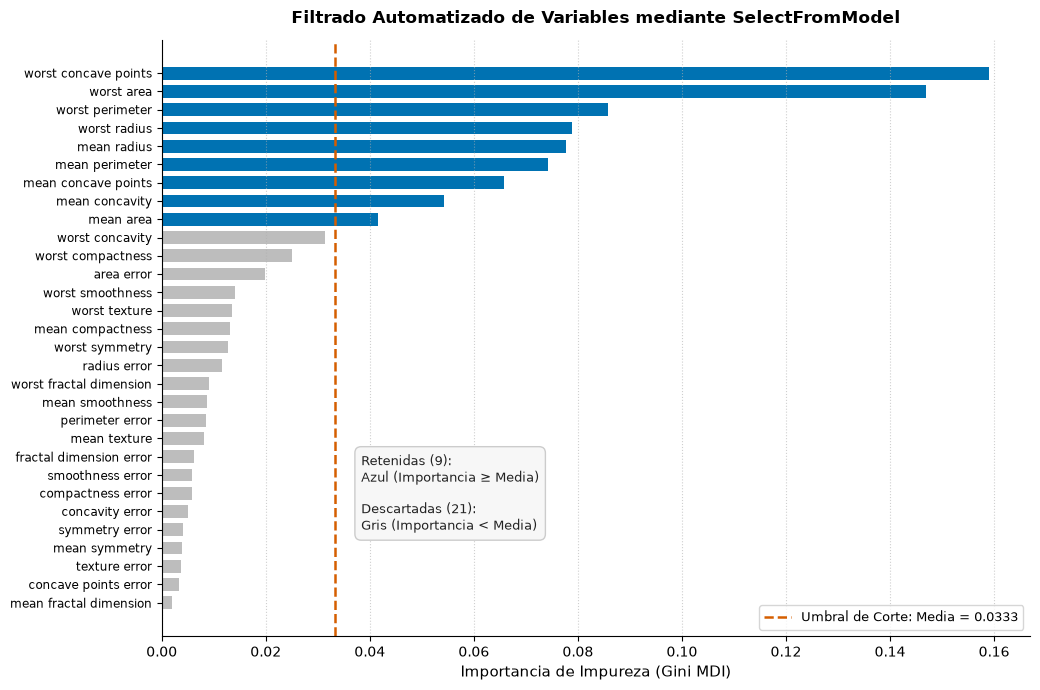

In [2]:
"""
Selección Automatizada de Características con SelectFromModel.
Dataset: Breast Cancer Wisconsin (scikit-learn) - 30 Características Reales.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# ==============================================================================
# 1. Carga de Datos y Partición Estratificada
# ==============================================================================
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Ajuste del Selector de Variables
# ==============================================================================
# Estimador base: Random Forest con subespacios aleatorios
rf_base = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)

# SelectFromModel con umbral dinámico en la media aritmética
selector = SelectFromModel(estimator=rf_base, threshold='mean')
selector.fit(X_train, y_train)

# Extracción de la máscara booleana y el umbral analítico
mascara = selector.get_support()
importancias = selector.estimator_.feature_importances_
umbral_corte = selector.threshold_

vars_seleccionadas = X.columns[mascara].tolist()
vars_descartadas = X.columns[~mascara].tolist()

print("=" * 65)
print("REDUCCIÓN AUTOMATIZADA CON SELECTFROMMODEL")
print("=" * 65)
print(f"Dimensiones Originales        : {X.shape} columnas")
print(f"Dimensiones Filtradas (Keep)  : {len(vars_seleccionadas)} columnas")
print(f"Columnas Eliminadas (Drop)    : {len(vars_descartadas)} columnas")
print(f"Umbral Analítico de Corte (θ) : {umbral_corte:.4f} (1/30 = 0.0333)")
print("=" * 65)

# ==============================================================================
# 3. Ensamblaje en un Pipeline de Producción (Anti-Data Leakage)
# ==============================================================================
pipeline_produccion = Pipeline([
    ('selector_rf', SelectFromModel(
        estimator=RandomForestClassifier(n_estimators=100, random_state=42),
        threshold='mean'
    )),
    ('escalador', StandardScaler()),
    ('clasificador_final', LogisticRegression(random_state=42))
])

# Entrenamiento conjunto y evaluación limpia en Test
pipeline_produccion.fit(X_train, y_train)
y_pred = pipeline_produccion.predict(X_test)
acc_test = accuracy_score(y_test, y_pred)

print(f"\nExactitud del Pipeline en Test Set: {acc_test * 100:.2f}%")
print(f"Variables Principales Retenidas:\n{vars_seleccionadas[:4]}")

# ==============================================================================
# 4. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, ax = plt.subplots(figsize=(10.5, 7), facecolor='white')
ax.set_facecolor('white')

# Ordenar características por importancia ascendente
indices_ord = np.argsort(importancias)
nombres_ord = [X.columns[i] for i in indices_ord]
valores_ord = importancias[indices_ord]
seleccionados_ord = mascara[indices_ord]

colores = ['#0072b2' if s else '#bdbdbd' for s in seleccionados_ord]

y_pos = np.arange(len(nombres_ord))
ax.barh(y_pos, valores_ord, color=colores, height=0.7)

# Línea discontinua que marca el umbral exacto de corte
ax.axvline(
    umbral_corte, color='#d55e00', linestyle='--', linewidth=1.8,
    label=f'Umbral de Corte: Media = {umbral_corte:.4f}'
)

ax.set_yticks(y_pos)
ax.set_yticklabels(nombres_ord, fontsize=8.5)
ax.set_xlabel("Importancia de Impureza (Gini MDI)", fontsize=10.5)
ax.set_title("Filtrado Automatizado de Variables mediante SelectFromModel",
             fontsize=12, fontweight='bold', pad=12)

# Cuadro informativo
ax.text(
    umbral_corte + 0.005, 4,
    f"Retenidas ({len(vars_seleccionadas)}):\nAzul (Importancia ≥ Media)\n\nDescartadas ({len(vars_descartadas)}):\nGris (Importancia < Media)",
    fontsize=9, color='#222222',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f7f7f7', edgecolor='#cccccc')
)

ax.grid(True, axis='x', linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', frameon=True, facecolor='white', fontsize=9.5)

plt.tight_layout()
plt.show()